<a href="https://colab.research.google.com/github/joymawu/TestRepo/blob/main/house_price_regression_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

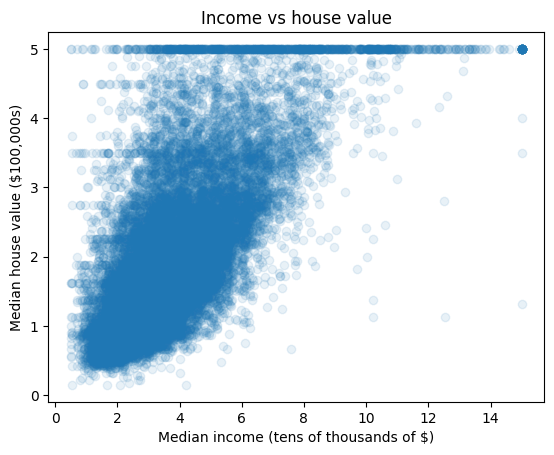

In [3]:
print(df.describe())
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.1)
plt.xlabel("Median income (tens of thousands of $)")
plt.ylabel("Median house value ($100,000s)")
plt.title("Income vs house value")
plt.show()

In [5]:
features = ["MedInc", "HouseAge", "AveRooms"]
X = df[features]
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
print(len(X_train), "training rows,", len(X_test), "test rows")

16512 training rows, 4128 test rows


In [7]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Intercept:", model.intercept_)
for name, coef in zip(features, model.coef_):
  print(name, coef)

Intercept: 0.017295645283375904
MedInc 0.44475780249705166
HouseAge 0.01683623030810302
AveRooms -0.028149678155777576


In [8]:
predictions = model.predict(X_test)
print("Mean absolute error:", mean_absolute_error(y_test, predictions))
print("R-squared:", r2_score(y_test, predictions))

Mean absolute error: 0.6033213567335046
R-squared: 0.49717158850807075


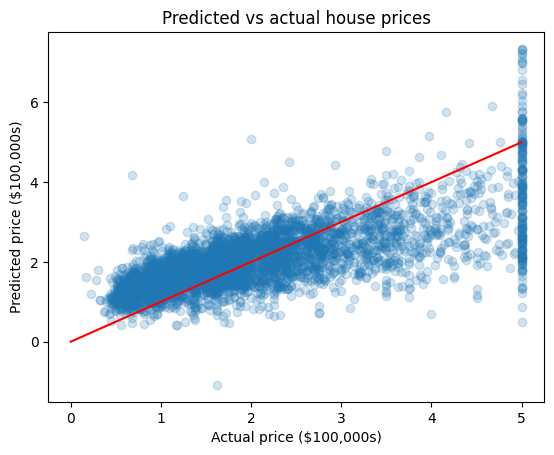

In [9]:
plt.scatter(y_test, predictions, alpha=0.2)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual price ($100,000s)")
plt.ylabel("Predicted price ($100,000s)")
plt.title("Predicted vs actual house prices")
plt.show()